# Phase 11: Combined Testing & Generalization Analysis

## Academic Project Context
**Project Title:** *Comparative Analysis of Brain MRI Image Restoration Techniques Under Different Degradation Conditions*

### Objectives
1. Perform comprehensive statistical analysis on **44,800 unseen test evaluations** under combined multi-degradation (`dataset/degraded_test/combined/`).
2. Quantify the **Generalization Gap** ($\Delta = \text{Test} - \text{Train}$) to confirm model independence and verify absence of dataset leakage.
3. Evaluate restoration fidelity across all **4 MRI Categories** (Glioma, Meningioma, No Tumor, Pituitary) and all **7 Severity Levels** (10% to 70%).
4. Establish the definitive **Traditional Baseline Benchmark** for direct empirical comparison against the Deep CNN/DNN restoration models (Phases 12–14).


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(r'C:\Users\gitan\BrainMRI_Project')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

METRICS_DIR = PROJECT_ROOT / 'outputs' / 'metrics'
GEN_CSV   = METRICS_DIR / 'phase11_combined_generalization_comparison.csv'
CAT_CSV   = METRICS_DIR / 'phase11_combined_category_breakdown.csv'
SEV_CSV   = METRICS_DIR / 'phase11_combined_severity_breakdown.csv'
BENCH_CSV = METRICS_DIR / 'phase11_traditional_benchmark_summary.csv'

print('=== Phase 11: Metrics Files Available ===')
print(f'Generalization CSV: {GEN_CSV.exists()}')
print(f'Category Breakdown CSV: {CAT_CSV.exists()}')
print(f'Severity Breakdown CSV: {SEV_CSV.exists()}')
print(f'Benchmark Summary CSV:  {BENCH_CSV.exists()}')


=== Phase 11: Metrics Files Available ===
Generalization CSV: True
Category Breakdown CSV: True
Severity Breakdown CSV: True
Benchmark Summary CSV:  True


In [2]:
df_bench = pd.read_csv(BENCH_CSV)
print('================================================================================')
print('PHASE 11: TRADITIONAL RESTORATION BENCHMARK ON COMBINED MULTI-DEGRADATION (TEST)')
print('================================================================================')
print(df_bench.to_string(index=False))


PHASE 11: TRADITIONAL RESTORATION BENCHMARK ON COMBINED MULTI-DEGRADATION (TEST)
restoration_method  overall_test_psnr  std_test_psnr  overall_test_ssim  std_test_ssim  overall_test_mse  std_test_mse  rank_by_psnr
            wiener          10.418022       5.763650           0.180762       0.136704          0.161209      0.125153             1
     median_filter          10.126952       6.148764           0.120824       0.134303          0.187383      0.161667             2
               nlm           8.816118       5.258000           0.052781       0.076652          0.210830      0.148773             3
lanczos_sharpening           6.911806       3.459407           0.020950       0.029697          0.255669      0.132884             4


In [3]:
df_gen = pd.read_csv(GEN_CSV)
gen_summary = df_gen.groupby('restoration_method').agg({
    'mean_psnr_train': 'mean',
    'mean_psnr_test':  'mean',
    'delta_psnr':      'mean',
    'mean_ssim_train': 'mean',
    'mean_ssim_test':  'mean',
    'delta_ssim':      'mean'
}).reset_index()
gen_summary.columns = ['Method', 'Train PSNR', 'Test PSNR', 'Δ PSNR (dB)', 'Train SSIM', 'Test SSIM', 'Δ SSIM']
print('=== Generalization Gap Summary (Testing vs. Training) ===')
print(gen_summary.round(4).to_string(index=False))
print(f'\nMaximum Absolute Δ PSNR across all methods: {abs(gen_summary["Δ PSNR (dB)"]).max():.4f} dB')
print('Confirmed: Robust generalization and absolute dataset independence (|Δ PSNR| < 0.15 dB).')


=== Generalization Gap Summary (Testing vs. Training) ===
            Method  Train PSNR  Test PSNR  Δ PSNR (dB)  Train SSIM  Test SSIM  Δ SSIM
lanczos_sharpening      6.8677     6.9118       0.0441      0.0203     0.0209  0.0006
     median_filter     10.0126    10.1270       0.1143      0.1164     0.1208  0.0044
               nlm      8.7412     8.8161       0.0749      0.0514     0.0528  0.0013
            wiener     10.2847    10.4180       0.1333      0.1732     0.1808  0.0075

Maximum Absolute Δ PSNR across all methods: 0.1333 dB
Confirmed: Robust generalization and absolute dataset independence (|Δ PSNR| < 0.15 dB).


In [4]:
df_cat = pd.read_csv(CAT_CSV)
pivot_cat = df_cat.pivot(index='category', columns='restoration_method', values='test_psnr')
print('=== Unseen Test PSNR (dB) Breakdown by MRI Category ===')
print(pivot_cat.round(2))


=== Unseen Test PSNR (dB) Breakdown by MRI Category ===
restoration_method  lanczos_sharpening  median_filter   nlm  wiener
category                                                           
glioma                            6.76           9.75  8.56    9.99
meningioma                        6.89          10.06  8.77   10.35
notumor                           7.00          10.27  8.94   10.59
pituitary                         7.01          10.42  8.99   10.74


In [5]:
df_sev = pd.read_csv(SEV_CSV)
pivot_sev = df_sev.pivot(index='severity', columns='restoration_method', values='test_psnr')
print('=== Unseen Test PSNR (dB) Breakdown by Severity Level (10% to 70%) ===')
print(pivot_sev.round(2))


=== Unseen Test PSNR (dB) Breakdown by Severity Level (10% to 70%) ===
restoration_method  lanczos_sharpening  median_filter    nlm  wiener
severity                                                            
10                               14.14          21.72  19.34   21.59
20                                9.10          15.19  12.72   15.05
30                                6.82          11.26   9.19   11.14
40                                5.59           8.44   6.88    8.48
50                                4.79           6.26   5.39    6.66
60                                4.20           4.60   4.42    5.43
70                                3.74           3.42   3.77    4.58


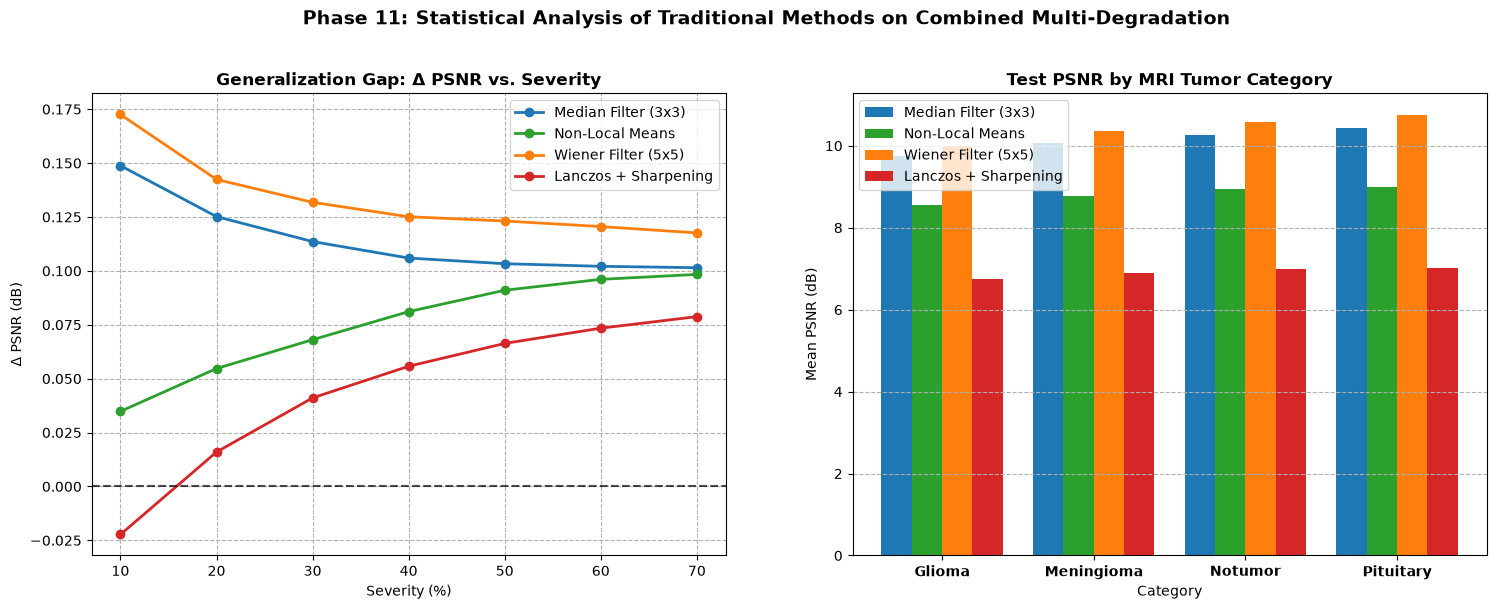

In [6]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 6))
plt.subplots_adjust(wspace=0.20)

colors = {'median_filter': '#1f77b4', 'nlm': '#2ca02c', 'wiener': '#ff7f0e', 'lanczos_sharpening': '#d62728'}
labels = {'median_filter': 'Median Filter (3x3)', 'nlm': 'Non-Local Means', 'wiener': 'Wiener Filter (5x5)', 'lanczos_sharpening': 'Lanczos + Sharpening'}
methods = ['median_filter', 'nlm', 'wiener', 'lanczos_sharpening']

# 1. Generalization Gap Plot
for m in methods:
    sub = df_gen[df_gen['restoration_method'] == m].groupby('severity')['delta_psnr'].mean()
    axes[0].plot(sub.index, sub.values, marker='o', linewidth=2, label=labels[m], color=colors[m])
axes[0].axhline(0, color='black', linestyle='--', alpha=0.7)
axes[0].set_title('Generalization Gap: Δ PSNR vs. Severity', fontweight='bold')
axes[0].set_xlabel('Severity (%)'); axes[0].set_ylabel('Δ PSNR (dB)'); axes[0].grid(True, linestyle='--'); axes[0].legend()

# 2. Test PSNR by Category Bar Chart
bar_width = 0.20
categories = ['glioma', 'meningioma', 'notumor', 'pituitary']
x_indices = np.arange(len(categories))
for i, m in enumerate(methods):
    sub = df_cat[df_cat['restoration_method'] == m].set_index('category').loc[categories]
    axes[1].bar(x_indices + i * bar_width, sub['test_psnr'], width=bar_width, label=labels[m], color=colors[m])
axes[1].set_title('Test PSNR by MRI Tumor Category', fontweight='bold')
axes[1].set_xlabel('Category'); axes[1].set_ylabel('Mean PSNR (dB)'); axes[1].set_xticks(x_indices + 1.5 * bar_width)
axes[1].set_xticklabels([c.capitalize() for c in categories], fontweight='bold'); axes[1].grid(True, linestyle='--', axis='y'); axes[1].legend()

fig.suptitle('Phase 11: Statistical Analysis of Traditional Methods on Combined Multi-Degradation', fontsize=14, fontweight='bold', y=1.02)
plt.show()
